# 托卡马克粒子轨道探索器 — 演示

本笔记本展示以下内容：
1. 托卡马克磁场中 Boris 推进器的能量守恒。
2. 磁镜磁场中磁矩的守恒行为。
3. Boris 算法的二阶收敛性验证。
4. 香蕉轨道（导心近似）。

In [1]:
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# 设置中文字体，按常见系统字体依次尝试
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "WenQuanYi Micro Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

from src.particles import Particle
from src.fields import TokamakField, MirrorField
from src.integrators import boris_integrate, guiding_center_integrate
from src.diagnostics import kinetic_energy, magnetic_moment

PROTON_MASS = 1.6726219e-27
PROTON_CHARGE = 1.6021766e-19
E = lambda x, y, z: np.zeros(3)

## 托卡马克磁场

对于圆截面、大环径比托卡马克，磁场可写为：
$$B_\phi = B_0 \frac{R_0}{R}, \quad B_\theta = \frac{r}{R q(r)} B_\phi$$

其中 $B_\phi$ 为环向场，$B_\theta$ 为极向场，$q(r)$ 为安全因子剖面。

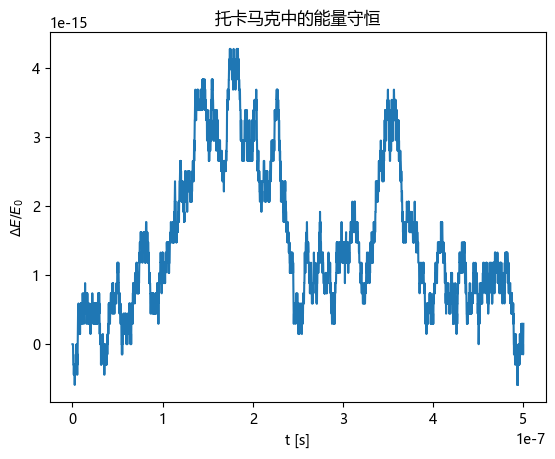

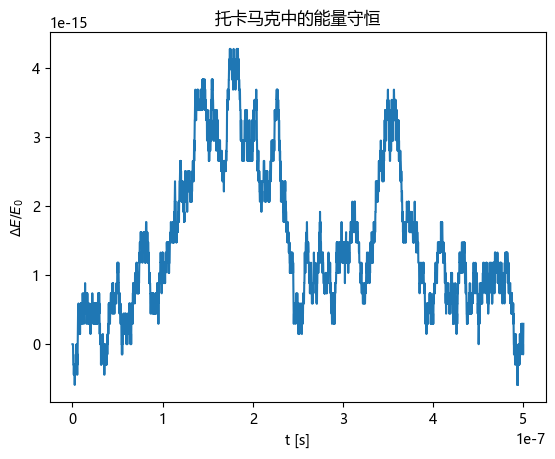

In [2]:
field = TokamakField(B0=5.0, R0=10.0, a=1.0, q0=1.0, q1=2.0)
v = np.array([1e5, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.2, 0.0, 0.0]), v)
result = boris_integrate(field, E, p, dt=1e-10, n_steps=5000)

energies = np.array([kinetic_energy(vv, PROTON_MASS) for vv in result["velocity"]])
fig, ax = plt.subplots()
ax.plot(result["times"], (energies - energies[0]) / energies[0])
ax.set_xlabel("t [s]")
ax.set_ylabel(r"$\Delta E / E_0$")
ax.set_title("托卡马克中的能量守恒")
fig

## 磁镜磁场

轴上磁场强度随轴向位置变化：
$$B_z(z) = B_0 \left(1 + b_m \frac{z^2}{L^2}\right)$$

由磁场无散条件 $\nabla \cdot \mathbf{B} = 0$ 可导出径向磁场：
$$B_r(r,z) = -\frac{r}{2} \frac{dB_z}{dz}$$

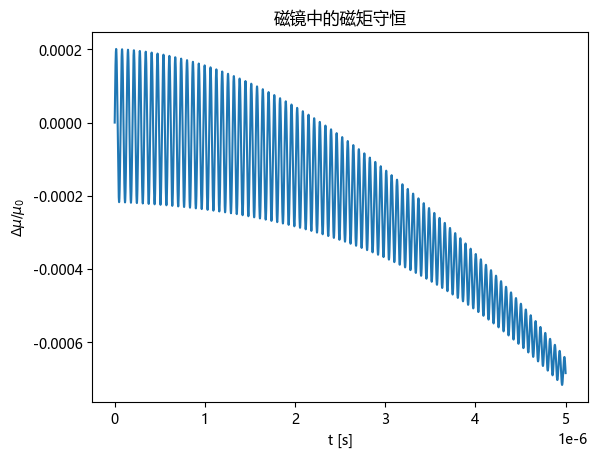

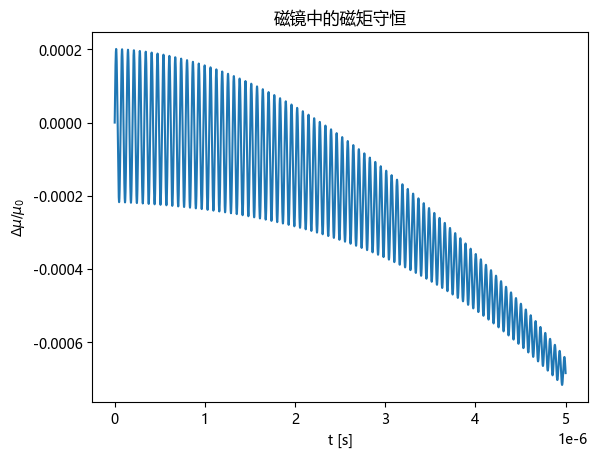

In [3]:
field = MirrorField(B0=1.0, bm=4.0, L=1.0)
v = np.array([1e4, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([0.01, 0.0, 0.0]), v)
result = boris_integrate(field, E, p, dt=1e-9, n_steps=5000)

mus = np.array([magnetic_moment(vv, field, *xx) for vv, xx in zip(result["velocity"], result["trajectory"])])
fig, ax = plt.subplots()
ax.plot(result["times"], (mus - mus[0]) / mus[0])
ax.set_xlabel("t [s]")
ax.set_ylabel(r"$\Delta \mu / \mu_0$")
ax.set_title("磁镜中的磁矩守恒")
fig

## Boris 算法收敛性

Boris 推进器具有二阶精度。下面以高分辨率计算结果作为参考，比较不同时间步长下最终位置的误差。

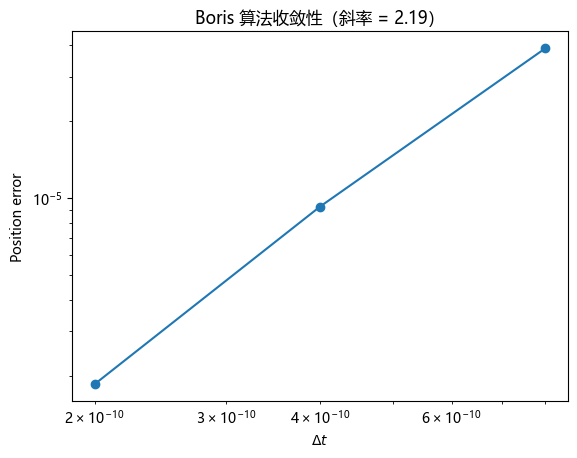

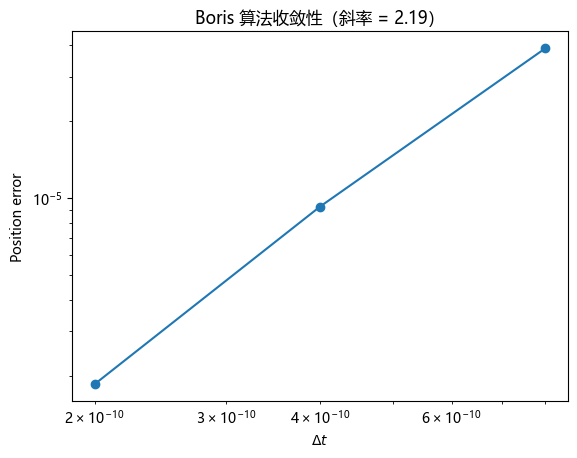

In [4]:
from src.diagnostics import convergence_test

field = MirrorField(B0=1.0, bm=2.0, L=1.0)
v = np.array([1e5, 0.0, 5e4])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([0.01, 0.0, 0.0]), v)
dt_list = [2e-10, 4e-10, 8e-10]
result = convergence_test(field, E, p, dt_ref=1e-10, n_steps_ref=8000, dt_list=dt_list)

slope = np.polyfit(np.log(result["dt_list"]), np.log(result["errors"]), 1)[0]
fig, ax = plt.subplots()
ax.loglog(result["dt_list"], result["errors"], "o-")
ax.set_xlabel(r"$\Delta t$")
ax.set_ylabel("Position error")
ax.set_title(f"Boris 算法收敛性（斜率 = {slope:.2f}）")
fig

## 香蕉轨道（导心近似）

在托卡马克中，被磁场镜效应捕获的粒子会形成香蕉轨道。由于 Boris 全粒子推进在长时间内会出现磁矩漂移，这里使用导心近似（假设磁矩守恒）来展示完整的香蕉轨道。

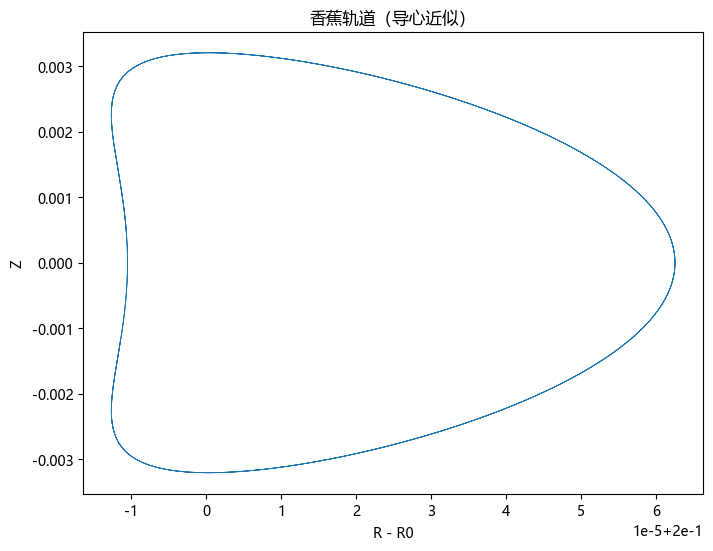

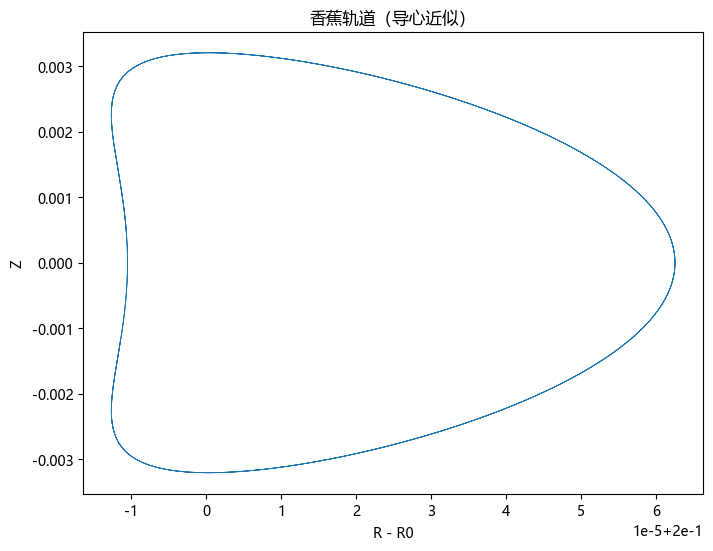

In [5]:
field = TokamakField(B0=5.0, R0=10.0, a=1.0, q0=1.0, q1=2.0)
# 被磁镜效应捕获的粒子：垂直速度远大于平行速度
v = np.array([2e5, 0.0, 5e3])
p = Particle(PROTON_CHARGE, PROTON_MASS, np.array([10.2, 0.0, 0.0]), v)

# 导心近似用于展示完整香蕉轨道；Boris 全轨道因 μ 漂移不适合直接跑完整 bounce。
result_gc = guiding_center_integrate(field, p, dt=5e-8, n_steps=200000)

R_g = np.sqrt(result_gc["trajectory"][:, 0] ** 2 + result_gc["trajectory"][:, 1] ** 2)
Z_g = result_gc["trajectory"][:, 2]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(R_g - 10.0, Z_g, lw=0.6)
ax.set_xlabel("R - R0")
ax.set_ylabel("Z")
ax.set_title("香蕉轨道（导心近似）")
fig